# 1 — The baseline failure

**What this notebook establishes.** Boltz-2, run unperturbed on 8SGE, builds the
wrong atropisomer almost every time: 1 of 41 draws lands in the crystal's basin.
The two answers are not two poses but the two senses of one hindered bond, so the
failure is one-dimensional and has a natural order parameter — the axial torsion
C12–C11–N1–C3.

**What it needs.** `numpy`, `matplotlib`, and this repository. Nothing else, and
no GPU: the draws are already committed under `data/poses/`. Every number below is
recomputed from coordinates rather than read from a results table, and checked
against the stored values.


In [1]:
import sys, pathlib

ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
            if (p / 'src' / 'cofolding_tts').is_dir())
sys.path.insert(0, str(ROOT / 'src'))      # unneeded after `pip install -e .`

import numpy as np
import matplotlib.pyplot as plt
import cofolding_tts
from cofolding_tts.pose import coordinate_rmsd
from cofolding_tts import basin

print('cofolding_tts', cofolding_tts.__version__, 'from', ROOT)

cofolding_tts 0.1.0 from /mnt/hdd2/BindingAffinityPredictor/Cofolding_TestTimeScaling


## The committed draws

`8sge_poses.npz` holds every pose this repository has produced, as ligand
coordinates already aligned on the protein, next to the deposited ligand in the
same frame. This notebook uses the `control` arm: 41 draws with no intervention.


In [2]:
poses = np.load(ROOT / 'data' / 'poses' / '8sge_poses.npz', allow_pickle=True)
print({k: poses[k].shape for k in poses.files})

is_control = poses['arm'] == 'control'
coords  = poses['coords'][is_control]        # (n, 33, 3), protein-aligned
crystal = poses['crystal']                   # (33, 3), the deposited ligand
names   = [str(n) for n in poses['atom_names']]
print(f'{len(coords)} unperturbed draws, {coords.shape[1]} heavy atoms')

{'run': (242,), 'arm': (242,), 'coords': (242, 33, 3), 'crystal': (33, 3), 'rmsd': (242,), 'torsion': (242,), 'axis_correct': (242,), 'atom_names': (33,), 'elements': (33,)}
41 unperturbed draws, 33 heavy atoms


## Check 1 — the RMSD, recomputed

Against the crystal, never against a predicted or injected pose. 8SGE's ligand has
a single graph mapping, so the symmetry-corrected RMSD and the direct one coincide
and `coordinate_rmsd` is enough here.


In [3]:
rmsd = np.array([coordinate_rmsd(p, crystal) for p in coords])
stored = poses['rmsd'][is_control]
print(f'max |recomputed - stored| = {np.abs(rmsd - stored).max():.2e} A')
print(f'median {np.median(rmsd):.2f} A, range {rmsd.min():.2f} to {rmsd.max():.2f} A')

max |recomputed - stored| = 4.87e-04 A
median 6.77 A, range 0.93 to 8.28 A


## Check 2 — the order parameter

The axial torsion is the dihedral about the hindered bond. It is frame-invariant,
so it can be read off the coordinates with no alignment at all, and the deposited
structure gives it a ground truth at **-101.4°**.


In [4]:
AXIS = ('C12', 'C11', 'N1', 'C3')


def dihedral(xyz, idx):
    """Signed torsion in degrees about the bond idx[1]-idx[2]."""
    b0 = xyz[idx[0]] - xyz[idx[1]]
    b1 = xyz[idx[2]] - xyz[idx[1]]
    b2 = xyz[idx[3]] - xyz[idx[2]]
    b1 = b1 / np.linalg.norm(b1)
    v = b0 - np.dot(b0, b1) * b1
    w = b2 - np.dot(b2, b1) * b1
    return np.degrees(np.arctan2(np.dot(np.cross(b1, v), w), np.dot(v, w)))


idx = [names.index(a) for a in AXIS]
torsion = np.array([dihedral(p, idx) for p in coords])
print(f'max |recomputed - stored| = {basin.separation(torsion, poses["torsion"][is_control]).max():.2e} deg')
print(f'crystal sits at {dihedral(crystal, idx):+.1f} deg (deposited: {basin.CRYSTAL_TORSION:+.1f})')

max |recomputed - stored| = 4.82e-02 deg
crystal sits at -101.4 deg (deposited: -101.4)


## The result

`cofolding_tts.basin` holds the criterion the whole repository scores by: within
40° of a measured basin centre, and nearer to that one than to the other. A pose
further than 40° from both is **neither** — it has the crystal's sign without its
rotamer, and counting those as rescues would flatter every arm that produces them.


In [5]:
label = basin.classify(torsion)
correct = label == 'correct'

for name, n in basin.counts(torsion).items():
    print(f'{name:>7} basin: {n:2d} of {len(torsion)}')
print(f'under 2 A    : {(rmsd < 2).sum():2d} of {len(torsion)}')
print()
for name in ('correct', 'wrong'):
    sel = label == name
    if sel.any():
        print(f'{name:>7} basin: centre {basin.circular_mean(torsion[sel]):+7.1f} deg, '
              f'circular SD {(basin.circular_sd(torsion[sel]) if sel.sum() > 1 else 0.0):5.1f} deg, '
              f'median RMSD {np.median(rmsd[sel]):.2f} A')
print(f'\nbasin centres, as measured over 260 poses: '
      f'{basin.CORRECT_CENTRE:+.1f} and {basin.WRONG_CENTRE:+.1f} deg, '
      f'{basin.separation(basin.CORRECT_CENTRE, basin.WRONG_CENTRE):.1f} apart')

correct basin:  1 of 41
  wrong basin: 39 of 41
neither basin:  1 of 41
under 2 A    :  1 of 41

correct basin: centre  -112.4 deg, circular SD   0.0 deg, median RMSD 0.93 A
  wrong basin: centre   +69.1 deg, circular SD   9.5 deg, median RMSD 6.77 A

basin centres, as measured over 260 poses: -112.6 and +68.7 deg, 178.7 apart


## The picture

Two spikes, nothing in between, and the model sits in the wrong one. That is what
makes this a basin problem rather than a precision problem — and what every later
notebook intervenes on.


wrote results/figures/nb01_baseline.png


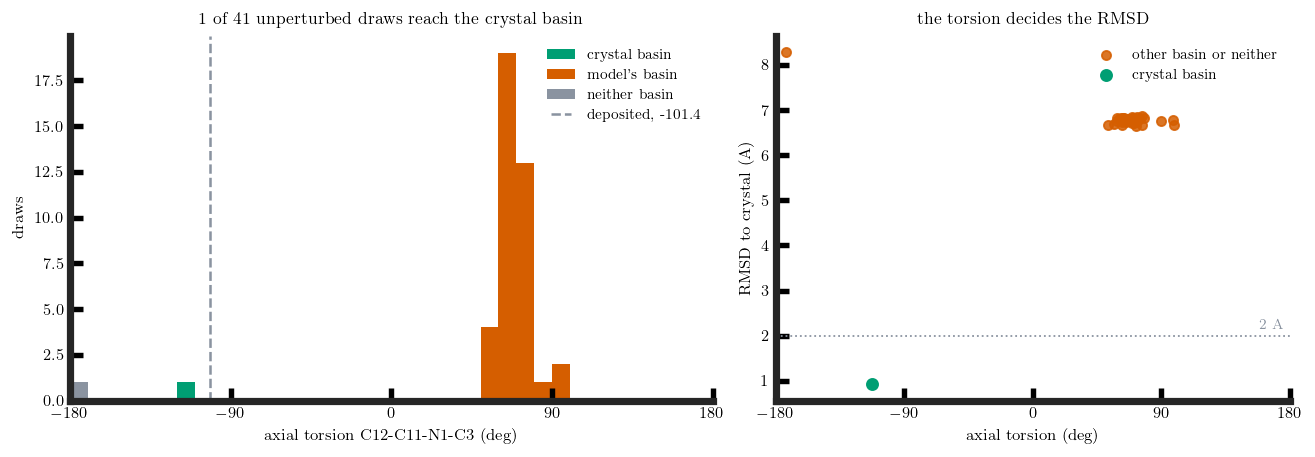

In [6]:
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 9,
                     'axes.labelsize': 9, 'axes.titlesize': 9.5,
                     'xtick.labelsize': 8.5, 'ytick.labelsize': 8.5})
fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 3.4), dpi=130,
                             gridspec_kw={'width_ratios': [1.25, 1]},
                             constrained_layout=True)
GREEN, ORANGE, GREY = '#009e73', '#d55e00', '#8a93a0'

edges = np.arange(-180, 190, 10)
ax.hist(torsion[label == 'correct'], bins=edges, color=GREEN, label='crystal basin')
ax.hist(torsion[label == 'wrong'], bins=edges, color=ORANGE, label="model's basin")
ax.hist(torsion[label == 'neither'], bins=edges, color=GREY, label='neither basin')
ax.axvline(basin.CRYSTAL_TORSION, color=GREY, lw=1.4, ls='--', label='deposited, -101.4')
ax.set_xlim(-180, 180); ax.set_xticks(np.arange(-180, 181, 90))
ax.set_xlabel('axial torsion C12-C11-N1-C3 (deg)'); ax.set_ylabel('draws')
ax.set_title(f'{correct.sum()} of {len(correct)} unperturbed draws reach the crystal basin')
ax.legend(fontsize=8, frameon=False)

bx.scatter(torsion[label != 'correct'], rmsd[label != 'correct'], s=26, color=ORANGE, alpha=.85, label='other basin or neither')
bx.scatter(torsion[correct], rmsd[correct], s=38, color=GREEN, label='crystal basin')
bx.axhline(2.0, color=GREY, lw=1.0, ls=':')
bx.text(175, 2.1, '2 A', ha='right', va='bottom', fontsize=8, color=GREY)
bx.set_xlim(-180, 180); bx.set_xticks(np.arange(-180, 181, 90))
bx.set_xlabel('axial torsion (deg)'); bx.set_ylabel('RMSD to crystal (A)')
bx.set_title('the torsion decides the RMSD')
bx.legend(fontsize=8, frameon=False)

for a in (ax, bx):
    a.spines[['top', 'right']].set_visible(False)
out = ROOT / 'results' / 'figures' / 'nb01_baseline.png'
fig.savefig(out, bbox_inches='tight')
print('wrote', out.relative_to(ROOT))

## What this fixes for the notebooks that follow

- The failure is **bimodal**, not diffuse. Nothing lands between the basins, so a
  draw either has the bond the right way round or it does not.
- The torsion **decides** the RMSD: every pose in the crystal basin is close, every
  pose in the other one is about 6 Å away. One scalar is enough to score an arm.
- The baseline rate is **1 of 41**, with one further draw landing in neither basin. Any intervention has to be read against that
  number and against the same 41 conditionings.

**Regenerating the draws** needs a GPU, a Boltz-2 install, and the checkpoint:

```bash
export BOLTZ_CHECKPOINT=/path/to/boltz2_conf.ckpt
export BOLTZ_CACHE=/path/to/boltz/cache
python scripts/run_8sge.py --arm control --draws 41
python scripts/score_8sge.py --runs runs
```

Next: **2 — destroying the ligand rows of the trunk**, the intervention that moves
that 2 of 41.
